In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar dataset
df = pd.read_csv("./data/steam_game_hits.csv")

# Dimensiones
print(f"Cantidad de juegos: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")

# Primeras filas
# display(df.head())

# Valores existentes en hit
print(df["hit"].value_counts(dropna=False))

# Verificar valores únicos
print("Valores únicos:", sorted(df["hit"].dropna().unique()))

# Verificar valores nulos
print("Valores nulos:", df["hit"].isna().sum())

# Cantidad de juegos por clase
cantidad = df["hit"].value_counts().sort_index()

# Porcentaje de cada clase
porcentaje = df["hit"].value_counts(normalize=True).sort_index() * 100

# Tabla resumen
distribucion = pd.DataFrame({
    "Cantidad": cantidad,
    "Porcentaje": porcentaje
})

distribucion.index = ["No Hit (0)", "Hit (1)"]

display(distribucion.round(2))

# Relación entre clases
no_hit = cantidad.get(0, 0)
hit = cantidad.get(1, 0)

print(f"Juegos Hit: {hit}")
print(f"Juegos No Hit: {no_hit}")

if hit > 0:
    print(f"Relación No Hit / Hit: {no_hit / hit:.2f}:1")

Cantidad de juegos: 8000
Cantidad de columnas: 22


,game_id,title,genre,release_year,is_indie,team_size,price_usd,has_multiplayer,early_access,controller_support,...,file_size_gb,metacritic_score,steam_positive_pct,wishlists_k,trailer_views_k,num_reviews,owners_k,peak_concurrent_players,revenue_musd,hit
0,G00001,Iron Signal,RPG,2021,0,260,29.99,0,1,1,...,15.6,68,76,72.2,307.0,30195,520.0,7828,7.862,1
1,G00002,Frozen Pact,Adventure,2019,1,5,2.99,1,0,0,...,2.9,44,68,13.3,15.6,1442,31.0,122,0.067,0
2,G00003,Eternal Harvest,Platformer,2012,0,253,49.99,0,0,1,...,11.2,67,88,10.1,13.2,1897,87.7,471,2.064,0
3,G00004,Phantom Odyssey,Adventure,2023,1,12,9.99,0,0,0,...,1.7,96,99,106.3,219.1,179655,14294.9,129108,70.949,1
4,G00005,Iron Gate,RPG,2019,0,44,49.99,0,0,1,...,19.7,58,76,6.5,253.9,1491,35.8,130,1.447,0


hit
0    6400
1    1600
Name: count, dtype: int64
Valores únicos: [np.int64(0), np.int64(1)]
Valores nulos: 0


,Cantidad,Porcentaje
No Hit (0),6400,80.0
Hit (1),1600,20.0


Juegos Hit: 1600
Juegos No Hit: 6400
Relación No Hit / Hit: 4.00:1


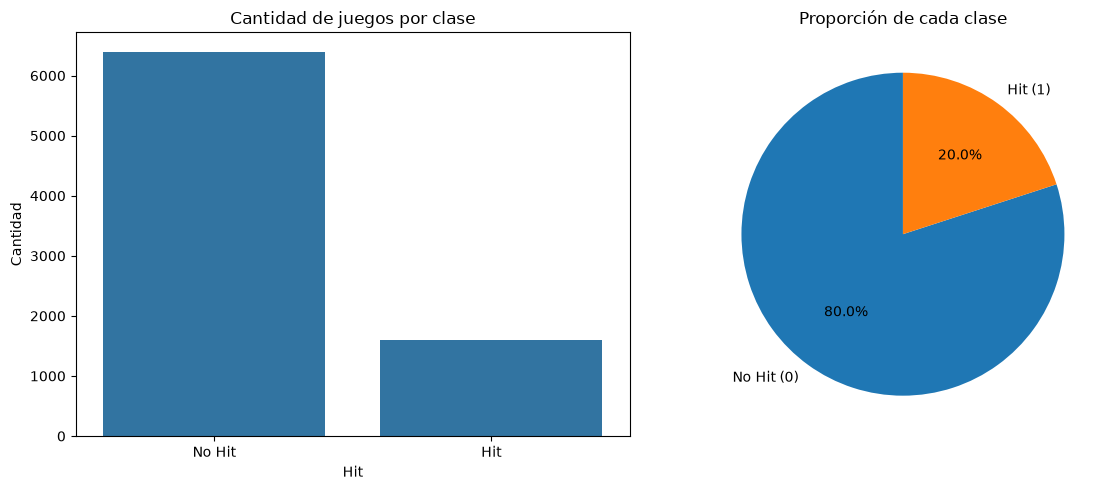

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Cantidades
sns.countplot(data=df, x="hit", ax=axes[0])
axes[0].set_title("Cantidad de juegos por clase")
axes[0].set_xlabel("Hit")
axes[0].set_ylabel("Cantidad")
axes[0].set_xticks([0, 1], ["No Hit", "Hit"])

# Porcentajes
axes[1].pie(
    distribucion["Cantidad"],
    labels=distribucion.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Proporción de cada clase")

plt.tight_layout()
plt.show()

In [10]:
feature_cols = [
    "genre",
    "release_year",
    "is_indie",
    "team_size",
    "price_usd",
    "has_multiplayer",
    "early_access",
    "controller_support",
    "languages_supported",
    "wishlists_k",
    "trailer_views_k"
]
target_col = "hit"

from sklearn.model_selection import train_test_split

# Variables predictoras y objetivo
X = df[feature_cols].copy()
y = df[target_col].copy()

# 70% entrenamiento, 30% temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# 15% validación, 15% prueba
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Dimensiones:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("Columnas de entrenamiento:")
print(X_train.columns.tolist())

print("\n¿Hay columnas excluidas?")
print(set(X_train.columns) - set(feature_cols))

print("\nValores nulos:")
display(X.isnull().sum())

Dimensiones:
X_train: (5600, 11)
X_val: (1200, 11)
X_test: (1200, 11)
Columnas de entrenamiento:
['genre', 'release_year', 'is_indie', 'team_size', 'price_usd', 'has_multiplayer', 'early_access', 'controller_support', 'languages_supported', 'wishlists_k', 'trailer_views_k']

¿Hay columnas excluidas?
set()

Valores nulos:


genre                  0
release_year           0
is_indie               0
team_size              0
price_usd              0
has_multiplayer        0
early_access           0
controller_support     0
languages_supported    0
wishlists_k            0
trailer_views_k        0
dtype: int64

In [12]:
# Tipos de datos
display(X.dtypes)

# Estadísticas descriptivas de variables numéricas
display(X.describe().T)

# Estadísticas de la variable categórica
display(X["genre"].value_counts())

# Cantidad de valores únicos
display(X.nunique().to_frame("Valores únicos"))

genre                      str
release_year             int64
is_indie                 int64
team_size                int64
price_usd              float64
has_multiplayer          int64
early_access             int64
controller_support       int64
languages_supported      int64
wishlists_k            float64
trailer_views_k        float64
dtype: object

,count,mean,std,min,25%,50%,75%,max
release_year,8000.0,2019.508375,3.915750,2012.0,2016.000,2020.00,2023.00,2025.00
is_indie,8000.0,0.615000,0.486626,0.0,0.000,1.00,1.00,1.00
team_size,8000.0,87.548250,121.054427,1.0,6.000,12.00,164.00,399.00
price_usd,8000.0,19.797738,17.533874,0.0,4.990,14.99,29.99,59.99
has_multiplayer,8000.0,0.434250,0.495689,0.0,0.000,0.00,1.00,1.00
early_access,8000.0,0.190125,0.392424,0.0,0.000,0.00,0.00,1.00
controller_support,8000.0,0.655000,0.475398,0.0,0.000,1.00,1.00,1.00
languages_supported,8000.0,8.079125,4.672135,1.0,4.000,7.00,11.00,26.00
wishlists_k,8000.0,24.426550,41.619561,0.1,5.675,12.40,27.20,1095.90
trailer_views_k,8000.0,93.066825,235.840232,0.3,16.000,38.70,93.70,14296.50


genre
Action        1178
RPG            954
Shooter        892
Adventure      755
Simulation     714
Strategy       683
Platformer     658
Survival       613
Puzzle         501
Horror         457
Sports         343
Racing         252
Name: count, dtype: int64

,Valores únicos
genre,12
release_year,14
is_indie,2
team_size,384
price_usd,10
has_multiplayer,2
early_access,2
controller_support,2
languages_supported,26
wishlists_k,1082


In [13]:
# Variables numéricas
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns

# Estadísticas de asimetría
skewness = X[numeric_cols].skew().sort_values(ascending=False)

display(
    pd.DataFrame({
        "Skewness": skewness,
        "Asimetría absoluta": skewness.abs()
    }).round(3)
)

,Skewness,Asimetría absoluta
trailer_views_k,30.317,30.317
wishlists_k,8.421,8.421
early_access,1.580,1.580
team_size,1.217,1.217
price_usd,1.049,1.049
languages_supported,0.763,0.763
has_multiplayer,0.265,0.265
release_year,-0.309,0.309
is_indie,-0.473,0.473
controller_support,-0.652,0.652


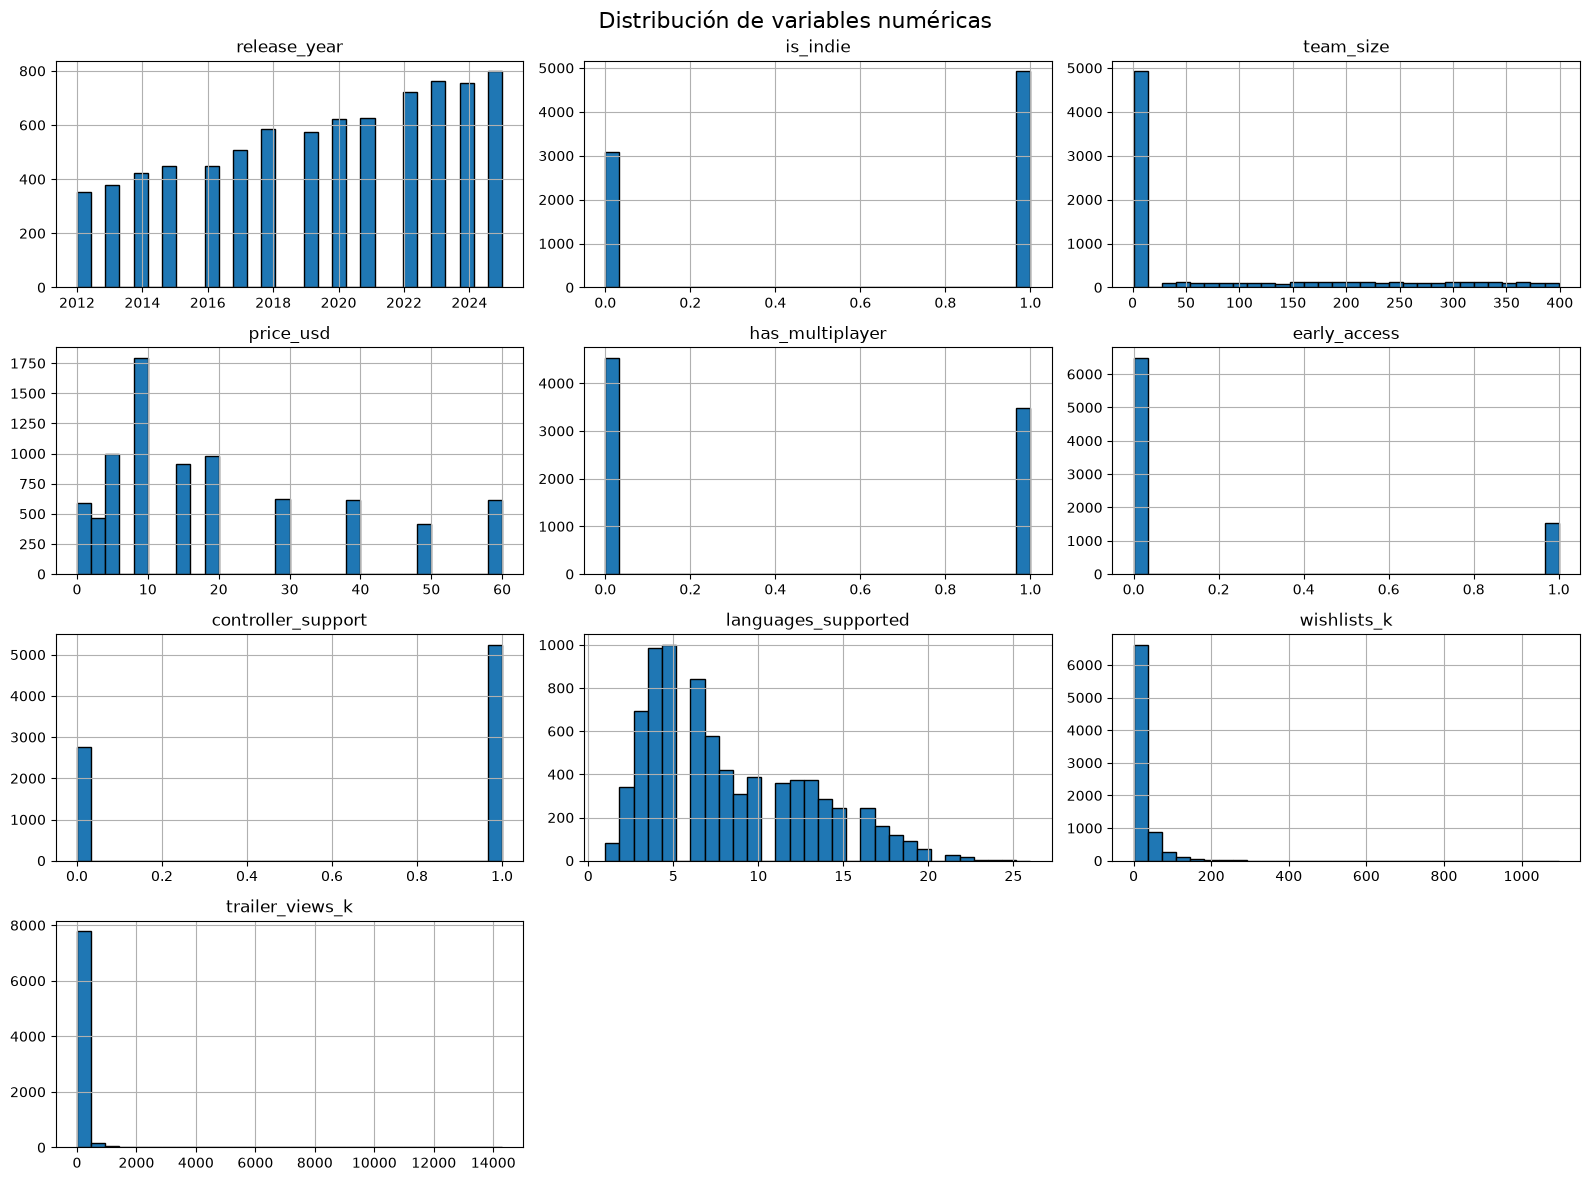

In [14]:
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns

X[numeric_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribución de variables numéricas", fontsize=16)
plt.tight_layout()
plt.show()

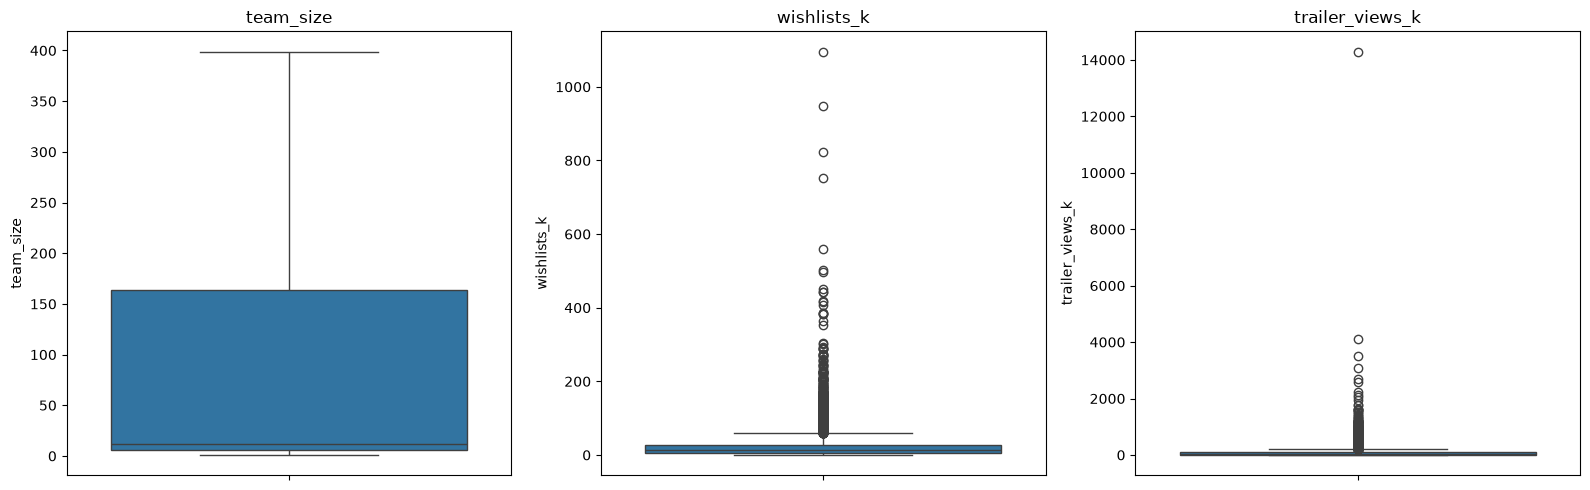

In [18]:
cols_to_check = [
    "team_size",
    "wishlists_k",
    "trailer_views_k"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for col, ax in zip(cols_to_check, axes):
    sns.boxplot(y=X[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Variables numéricas continuas
numeric_cols = [
    "release_year",
    "team_size",
    "price_usd",
    "languages_supported",
    "wishlists_k",
    "trailer_views_k"
]

# Variables binarias
binary_cols = [
    "is_indie",
    "has_multiplayer",
    "early_access",
    "controller_support"
]

# Preprocesamiento
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_cols),
        ("binary", "passthrough", binary_cols)
    ],
    remainder="drop"
)

# Ajustar exclusivamente con entrenamiento
X_train_processed = preprocessor.fit_transform(X_train)

# Transformar validación y prueba
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

Train: (5600, 10)
Validation: (1200, 10)
Test: (1200, 10)


In [21]:
# Crear vocabulario exclusivamente con los datos de entrenamiento
genres = sorted(X_train["genre"].unique())

genre_to_idx = {
    genre: idx + 1
    for idx, genre in enumerate(genres)
}

print("Vocabulario de géneros:")
print(genre_to_idx)

print("Cantidad de géneros:", len(genre_to_idx))

# Codificar género en cada conjunto
def encode_genre(series):
    return series.map(genre_to_idx).fillna(0).astype("int64").values

genre_train = encode_genre(X_train["genre"])
genre_val = encode_genre(X_val["genre"])
genre_test = encode_genre(X_test["genre"])

print("Train:", genre_train.shape)
print("Validation:", genre_val.shape)
print("Test:", genre_test.shape)

Vocabulario de géneros:
{'Action': 1, 'Adventure': 2, 'Horror': 3, 'Platformer': 4, 'Puzzle': 5, 'RPG': 6, 'Racing': 7, 'Shooter': 8, 'Simulation': 9, 'Sports': 10, 'Strategy': 11, 'Survival': 12}
Cantidad de géneros: 12
Train: (5600,)
Validation: (1200,)
Test: (1200,)


In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

print(torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("No hay GPU disponible. Activala en Entorno de ejecución > Cambiar tipo de entorno de ejecución.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Fijar semilla para reproducibilidad
torch.manual_seed(42)
np.random.seed(42)

# Dispositivo de entrenamiento
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

# Variables numéricas y binarias
X_train_tensor = torch.tensor(
    X_train_processed, dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_processed, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_processed, dtype=torch.float32
)

# Géneros
genre_train_tensor = torch.tensor(genre_train, dtype=torch.long)
genre_val_tensor = torch.tensor(genre_val, dtype=torch.long)
genre_test_tensor = torch.tensor(genre_test, dtype=torch.long)

# Variable objetivo
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32)

# Dataset y DataLoader
train_dataset = TensorDataset(
    X_train_tensor,
    genre_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    genre_val_tensor,
    y_val_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

True
PyTorch: 2.6.0+cu124
Torchvision: 0.21.0+cu124
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3080
VRAM: 10.0 GB
Dispositivo: cuda


In [24]:
import torch.nn as nn

class GameSuccessMLP(nn.Module):

    def __init__(self, num_numeric_features, num_genres, embedding_dim=6):

        super().__init__()

        # Entity Embedding
        self.genre_embedding = nn.Embedding(
            num_embeddings=num_genres + 1,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        # Red neuronal principal
        input_dim = num_numeric_features + embedding_dim

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.GELU(),
            nn.Dropout(0.2),

            nn.Linear(32, 1)
        )

    def forward(self, x_numeric, x_genre):

        # Aprender representación del género
        genre_vector = self.genre_embedding(x_genre)

        # Concatenar ambas entradas
        x = torch.cat(
            [x_numeric, genre_vector],
            dim=1
        )

        # Obtener logit
        return self.network(x).squeeze(1)

In [25]:
model = GameSuccessMLP(
    num_numeric_features=X_train_processed.shape[1],
    num_genres=len(genre_to_idx),
    embedding_dim=6
).to(device)

print(model)

GameSuccessMLP(
  (genre_embedding): Embedding(13, 6, padding_idx=0)
  (network): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [26]:
import torch.optim as optim

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

epochs = 100
patience = 10

In [27]:
from copy import deepcopy

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(epochs):

    # -------------------------
    # ENTRENAMIENTO
    # -------------------------
    model.train()
    train_loss_total = 0

    for x_num, x_genre, labels in train_loader:

        x_num = x_num.to(device)
        x_genre = x_genre.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(x_num, x_genre)

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * labels.size(0)

    train_loss = train_loss_total / len(train_dataset)

    # -------------------------
    # VALIDACIÓN
    # -------------------------
    model.eval()
    val_loss_total = 0

    with torch.no_grad():

        for x_num, x_genre, labels in val_loader:

            x_num = x_num.to(device)
            x_genre = x_genre.to(device)
            labels = labels.to(device)

            logits = model(x_num, x_genre)

            loss = criterion(logits, labels)

            val_loss_total += loss.item() * labels.size(0)

    val_loss = val_loss_total / len(val_dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    # -------------------------
    # EARLY STOPPING
    # -------------------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_model_state = deepcopy(model.state_dict())
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch+1:03d} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f}"
    )

    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping en época {epoch+1}")
        break

# Recuperar los mejores pesos
model.load_state_dict(best_model_state)

print("\nMejor Validation Loss:", best_val_loss)

Epoch 001 | Train Loss: 0.44631 | Val Loss: 0.37295
Epoch 002 | Train Loss: 0.36748 | Val Loss: 0.34025
Epoch 003 | Train Loss: 0.34936 | Val Loss: 0.32788
Epoch 004 | Train Loss: 0.33804 | Val Loss: 0.32603
Epoch 005 | Train Loss: 0.33383 | Val Loss: 0.32217
Epoch 006 | Train Loss: 0.33310 | Val Loss: 0.32503
Epoch 007 | Train Loss: 0.33000 | Val Loss: 0.31695
Epoch 008 | Train Loss: 0.33103 | Val Loss: 0.31582
Epoch 009 | Train Loss: 0.32864 | Val Loss: 0.31766
Epoch 010 | Train Loss: 0.32234 | Val Loss: 0.31601
Epoch 011 | Train Loss: 0.32158 | Val Loss: 0.31301
Epoch 012 | Train Loss: 0.32068 | Val Loss: 0.31199
Epoch 013 | Train Loss: 0.31521 | Val Loss: 0.31296
Epoch 014 | Train Loss: 0.31744 | Val Loss: 0.31045
Epoch 015 | Train Loss: 0.31365 | Val Loss: 0.31145
Epoch 016 | Train Loss: 0.31598 | Val Loss: 0.31202
Epoch 017 | Train Loss: 0.31362 | Val Loss: 0.31134
Epoch 018 | Train Loss: 0.31056 | Val Loss: 0.31056
Epoch 019 | Train Loss: 0.31021 | Val Loss: 0.31396
Epoch 020 | 

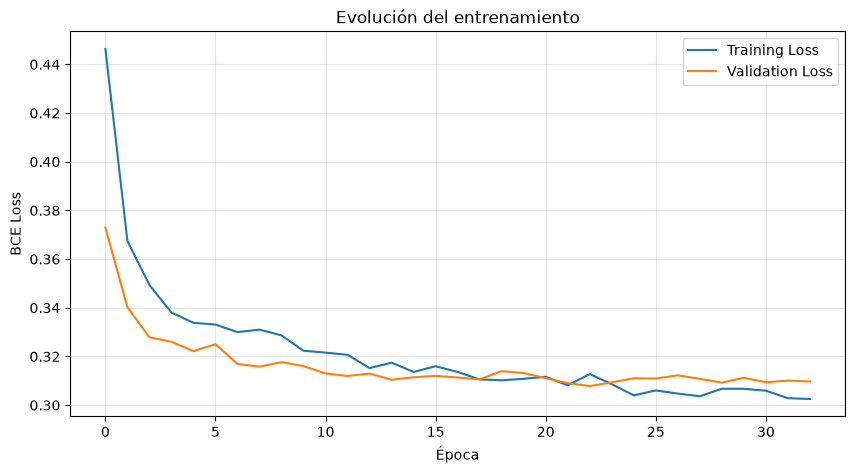

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Época")
plt.ylabel("BCE Loss")
plt.title("Evolución del entrenamiento")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

model.eval()

with torch.no_grad():
    logits = model(
        X_val_tensor.to(device),
        genre_val_tensor.to(device)
    )

    probabilities = torch.sigmoid(logits).cpu().numpy()

# Umbral inicial de clasificación
predictions = (probabilities >= 0.5).astype(int)

mlp_val_probs = probabilities.copy()

y_val_np = y_val.to_numpy()

In [30]:
print("MÉTRICAS DE VALIDACIÓN\n")

print(f"Accuracy:          {accuracy_score(y_val_np, predictions):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val_np, predictions):.4f}")
print(f"Precision:         {precision_score(y_val_np, predictions):.4f}")
print(f"Recall:            {recall_score(y_val_np, predictions):.4f}")
print(f"F1-score:          {f1_score(y_val_np, predictions):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_val_np, probabilities):.4f}")
print(f"PR-AUC:            {average_precision_score(y_val_np, probabilities):.4f}")

MÉTRICAS DE VALIDACIÓN

Accuracy:          0.8633
Balanced Accuracy: 0.7521
Precision:         0.6939
Recall:            0.5667
F1-score:          0.6239
ROC-AUC:           0.8989
PR-AUC:            0.6939


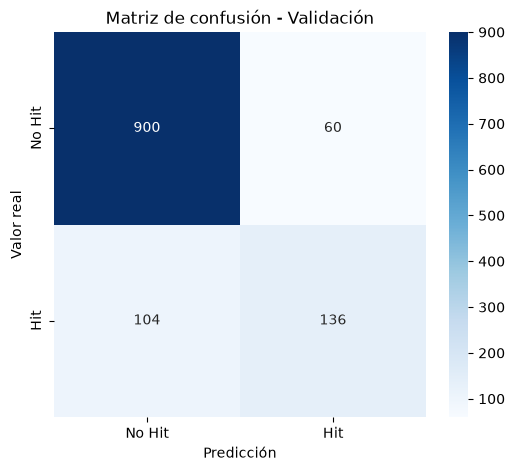

In [31]:
cm = confusion_matrix(y_val_np, predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Hit", "Hit"],
    yticklabels=["No Hit", "Hit"]
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - Validación")

plt.show()

In [32]:
print(
    classification_report(
        y_val_np,
        predictions,
        target_names=["No Hit", "Hit"],
        digits=4
    )
)

              precision    recall  f1-score   support

      No Hit     0.8964    0.9375    0.9165       960
         Hit     0.6939    0.5667    0.6239       240

    accuracy                         0.8633      1200
   macro avg     0.7951    0.7521    0.7702      1200
weighted avg     0.8559    0.8633    0.8580      1200



In [33]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.10, 0.81, 0.05)

results = []

for threshold in thresholds:

    predictions_temp = (probabilities >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_np, predictions_temp, zero_division=0
        ),
        "Recall": recall_score(
            y_val_np, predictions_temp, zero_division=0
        ),
        "F1": f1_score(
            y_val_np, predictions_temp, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(4))

,Threshold,Precision,Recall,F1
0,0.10,0.4288,0.9292,0.5868
1,0.15,0.4665,0.9000,0.6145
2,0.20,0.4988,0.8375,0.6252
3,0.25,0.5222,0.7833,0.6267
4,0.30,0.5566,0.7375,0.6344
5,0.35,0.6036,0.7042,0.6500
6,0.40,0.6353,0.6750,0.6545
7,0.45,0.6623,0.6375,0.6497
8,0.50,0.6939,0.5667,0.6239
9,0.55,0.7126,0.4958,0.5848


In [34]:
best_idx = threshold_results["F1"].idxmax()

print("Mejor umbral según F1:")
display(threshold_results.loc[[best_idx]].round(4))

Mejor umbral según F1:


,Threshold,Precision,Recall,F1
6,0.4,0.6353,0.675,0.6545


----
### modelos tradicionales 
#### Regresión Logística: baseline lineal y Random Forest: baseline basado en árboles

## Regresión Logística

In [35]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Preprocesamiento específico para Regresión Logística
logistic_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_cols),
        ("binary", "passthrough", binary_cols),
        ("genre", OneHotEncoder(handle_unknown="ignore"), ["genre"])
    ],
    remainder="drop"
)

# Pipeline completo
logistic_model = Pipeline(steps=[
    ("preprocessor", logistic_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Entrenamiento
logistic_model.fit(X_train, y_train)

print("Regresión Logística entrenada correctamente.")


Regresión Logística entrenada correctamente.


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Probabilidades de la clase Hit
logistic_val_probs = logistic_model.predict_proba(X_val)[:, 1]

# Clasificación con threshold 0.5
logistic_val_preds = (logistic_val_probs >= 0.5).astype(int)

# Métricas
print("=== Regresión Logística - Validation ===")
print(f"Accuracy:          {accuracy_score(y_val, logistic_val_preds):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, logistic_val_preds):.4f}")
print(f"Precision:         {precision_score(y_val, logistic_val_preds):.4f}")
print(f"Recall:            {recall_score(y_val, logistic_val_preds):.4f}")
print(f"F1-score:          {f1_score(y_val, logistic_val_preds):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_val, logistic_val_probs):.4f}")
print(f"Average Precision: {average_precision_score(y_val, logistic_val_probs):.4f}")

print("\nMatriz de confusión:")
print(confusion_matrix(y_val, logistic_val_preds))

print("\nReporte de clasificación:")
print(classification_report(
    y_val,
    logistic_val_preds,
    target_names=["No Hit", "Hit"]
))


=== Regresión Logística - Validation ===
Accuracy:          0.8608
Balanced Accuracy: 0.7052
Precision:         0.7589
Recall:            0.4458
F1-score:          0.5617
ROC-AUC:           0.8803
Average Precision: 0.6858

Matriz de confusión:
[[926  34]
 [133 107]]

Reporte de clasificación:
              precision    recall  f1-score   support

      No Hit       0.87      0.96      0.92       960
         Hit       0.76      0.45      0.56       240

    accuracy                           0.86      1200
   macro avg       0.82      0.71      0.74      1200
weighted avg       0.85      0.86      0.85      1200



## Random Forest

In [37]:

from sklearn.ensemble import RandomForestClassifier

# Preprocesamiento para Random Forest
rf_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_cols),
        ("binary", "passthrough", binary_cols),
        ("genre", OneHotEncoder(handle_unknown="ignore"), ["genre"])
    ],
    remainder="drop"
)

# Pipeline completo
rf_model = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenamiento
rf_model.fit(X_train, y_train)

print("Random Forest entrenado correctamente.")


Random Forest entrenado correctamente.


In [38]:

# Probabilidades de la clase Hit
rf_val_probs = rf_model.predict_proba(X_val)[:, 1]

# Clasificación con threshold 0.5
rf_val_preds = (rf_val_probs >= 0.5).astype(int)

# Métricas
print("=== Random Forest - Validation ===")
print(f"Accuracy:          {accuracy_score(y_val, rf_val_preds):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, rf_val_preds):.4f}")
print(f"Precision:         {precision_score(y_val, rf_val_preds):.4f}")
print(f"Recall:            {recall_score(y_val, rf_val_preds):.4f}")
print(f"F1-score:          {f1_score(y_val, rf_val_preds):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_val, rf_val_probs):.4f}")
print(f"Average Precision: {average_precision_score(y_val, rf_val_probs):.4f}")

print("\nMatriz de confusión:")
print(confusion_matrix(y_val, rf_val_preds))

print("\nReporte de clasificación:")
print(classification_report(
    y_val,
    rf_val_preds,
    target_names=["No Hit", "Hit"]
))


=== Random Forest - Validation ===
Accuracy:          0.8583
Balanced Accuracy: 0.7193
Precision:         0.7134
Recall:            0.4875
F1-score:          0.5792
ROC-AUC:           0.8957
Average Precision: 0.6970

Matriz de confusión:
[[913  47]
 [123 117]]

Reporte de clasificación:
              precision    recall  f1-score   support

      No Hit       0.88      0.95      0.91       960
         Hit       0.71      0.49      0.58       240

    accuracy                           0.86      1200
   macro avg       0.80      0.72      0.75      1200
weighted avg       0.85      0.86      0.85      1200



In [39]:

import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.10, 0.81, 0.05)

models_probs = {
    "Regresión Logística": logistic_val_probs,
    "Random Forest": rf_val_probs
}

results = []

for model_name, probabilities in models_probs.items():
    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        results.append({
            "Modelo": model_name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(y_val, predictions, zero_division=0),
            "Recall": recall_score(y_val, predictions, zero_division=0),
            "F1": f1_score(y_val, predictions, zero_division=0)
        })

threshold_results = pd.DataFrame(results)

# Mostrar el mejor threshold de cada modelo según F1
best_thresholds = (
    threshold_results
    .sort_values("F1", ascending=False)
    .groupby("Modelo")
    .head(1)
    .sort_values("F1", ascending=False)
)

print("Mejores umbrales por modelo:")
display(best_thresholds)

print("\nResultados completos:")
display(
    threshold_results.sort_values(
        ["Modelo", "Threshold"]
    ).reset_index(drop=True)
)


Mejores umbrales por modelo:


,Modelo,Threshold,Precision,Recall,F1
19,Random Forest,0.3,0.603960,0.7625,0.674033
2,Regresión Logística,0.2,0.570968,0.7375,0.643636



Resultados completos:


,Modelo,Threshold,Precision,Recall,F1
0,Random Forest,0.10,0.366129,0.945833,0.527907
1,Random Forest,0.15,0.424361,0.900000,0.576769
2,Random Forest,0.20,0.473441,0.854167,0.609212
3,Random Forest,0.25,0.533333,0.800000,0.640000
4,Random Forest,0.30,0.603960,0.762500,0.674033
5,Random Forest,0.35,0.642023,0.687500,0.663984
6,Random Forest,0.40,0.665158,0.612500,0.637744
7,Random Forest,0.45,0.695187,0.541667,0.608899
8,Random Forest,0.50,0.717791,0.487500,0.580645
9,Random Forest,0.55,0.748252,0.445833,0.558747


In [43]:

from sklearn.metrics import precision_recall_curve
import pandas as pd

models_probs = {
    "Regresión Logística": logistic_val_probs,
    "Random Forest": rf_val_probs,
    "MLP + Embedding": mlp_val_probs
}

# Si tu variable de probabilidades del MLP tiene otro nombre,
# reemplazá mlp_val_probs por el nombre que utilizaste anteriormente.

precision_limits = [0.60, 0.65, 0.70]

results = []

for model_name, probabilities in models_probs.items():

    precision, recall, thresholds = precision_recall_curve(
        y_val, probabilities
    )

    # El último elemento de precision y recall no tiene threshold asociado.
    precision = precision[:-1]
    recall = recall[:-1]

    for min_precision in precision_limits:

        valid_indices = [
            i for i, p in enumerate(precision)
            if p >= min_precision
        ]

        if not valid_indices:
            continue

        best_idx = max(valid_indices, key=lambda i: recall[i])

        results.append({
            "Modelo": model_name,
            "Precision mínima": min_precision,
            "Threshold": thresholds[best_idx],
            "Precision obtenida": precision[best_idx],
            "Recall obtenido": recall[best_idx],
            "F1": (
                2 * precision[best_idx] * recall[best_idx]
                / (precision[best_idx] + recall[best_idx])
            )
        })

display(
    pd.DataFrame(results).round(4)
)


,Modelo,Precision mínima,Threshold,Precision obtenida,Recall obtenido,F1
0,Regresión Logística,0.60,0.2316,0.6014,0.7042,0.6488
1,Regresión Logística,0.65,0.3040,0.6518,0.6083,0.6293
2,Regresión Logística,0.70,0.3781,0.7021,0.5500,0.6168
3,Random Forest,0.60,0.3033,0.6040,0.7625,0.6740
4,Random Forest,0.65,0.3833,0.6527,0.6500,0.6514
5,Random Forest,0.70,0.4600,0.7017,0.5292,0.6033
6,MLP + Embedding,0.60,0.3495,0.6014,0.7042,0.6488
7,MLP + Embedding,0.65,0.4164,0.6504,0.6667,0.6584
8,MLP + Embedding,0.70,0.5165,0.7021,0.5500,0.6168


In [44]:

# Obtener nombres de las features después del preprocesamiento
rf_feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

# Importancia calculada por Random Forest
rf_importances = rf_model.named_steps["classifier"].feature_importances_

# Tabla de importancia
rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
}).sort_values("Importance", ascending=False)

display(rf_importance_df.round(4))


,Feature,Importance
4,numeric__wishlists_k,0.3434
5,numeric__trailer_views_k,0.1972
1,numeric__team_size,0.0996
3,numeric__languages_supported,0.0746
0,numeric__release_year,0.0703
2,numeric__price_usd,0.0577
7,binary__has_multiplayer,0.0197
9,binary__controller_support,0.0167
8,binary__early_access,0.0132
10,genre__genre_Action,0.0114


In [45]:

# Agrupar las importancias de las categorías de genre
rf_importance_df["Original Feature"] = (
    rf_importance_df["Feature"]
    .str.replace("numeric__", "", regex=False)
    .str.replace("binary__", "", regex=False)
    .str.replace("genre__", "", regex=False)
    .str.replace(r"^genre_.*$", "genre", regex=True)
)

rf_grouped_importance = (
    rf_importance_df
    .groupby("Original Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(rf_grouped_importance.round(4))


,Original Feature,Importance
0,wishlists_k,0.3434
1,trailer_views_k,0.1972
2,team_size,0.0996
3,genre,0.0986
4,languages_supported,0.0746
5,release_year,0.0703
6,price_usd,0.0577
7,has_multiplayer,0.0197
8,controller_support,0.0167
9,early_access,0.0132


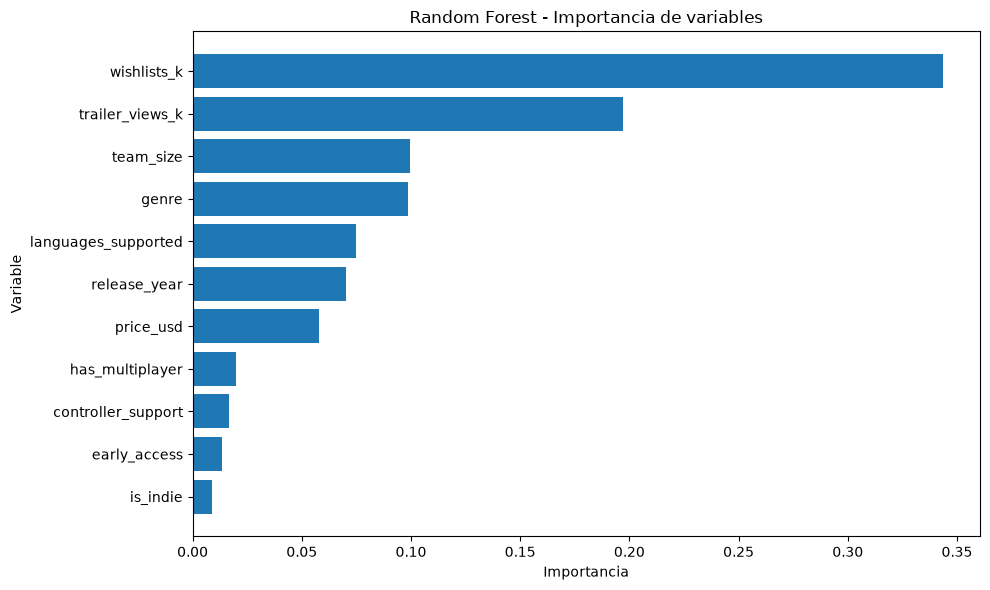

In [46]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    rf_grouped_importance["Original Feature"],
    rf_grouped_importance["Importance"]
)

plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.title("Random Forest - Importancia de variables")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [47]:

from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    rf_model,
    X_val,
    y_val,
    scoring=["roc_auc", "average_precision"],
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_val.columns,
    "ROC-AUC Importance": permutation_result["roc_auc"].importances_mean,
    "ROC-AUC Std": permutation_result["roc_auc"].importances_std,
    "AP Importance": permutation_result["average_precision"].importances_mean,
    "AP Std": permutation_result["average_precision"].importances_std
})

permutation_df = permutation_df.sort_values(
    "ROC-AUC Importance",
    ascending=False
)

display(permutation_df.round(4))


,Feature,ROC-AUC Importance,ROC-AUC Std,AP Importance,AP Std
9,wishlists_k,0.2576,0.0133,0.3941,0.0243
10,trailer_views_k,0.0265,0.0050,0.0507,0.0161
5,has_multiplayer,0.0051,0.0026,0.0121,0.0081
4,price_usd,0.0042,0.0026,0.0004,0.0065
1,release_year,0.0037,0.0015,0.0059,0.0050
7,controller_support,0.0033,0.0017,0.0037,0.0051
3,team_size,0.0011,0.0022,0.0051,0.0039
6,early_access,0.0008,0.0007,0.0005,0.0028
8,languages_supported,0.0002,0.0022,-0.0010,0.0069
0,genre,0.0002,0.0030,-0.0040,0.0069


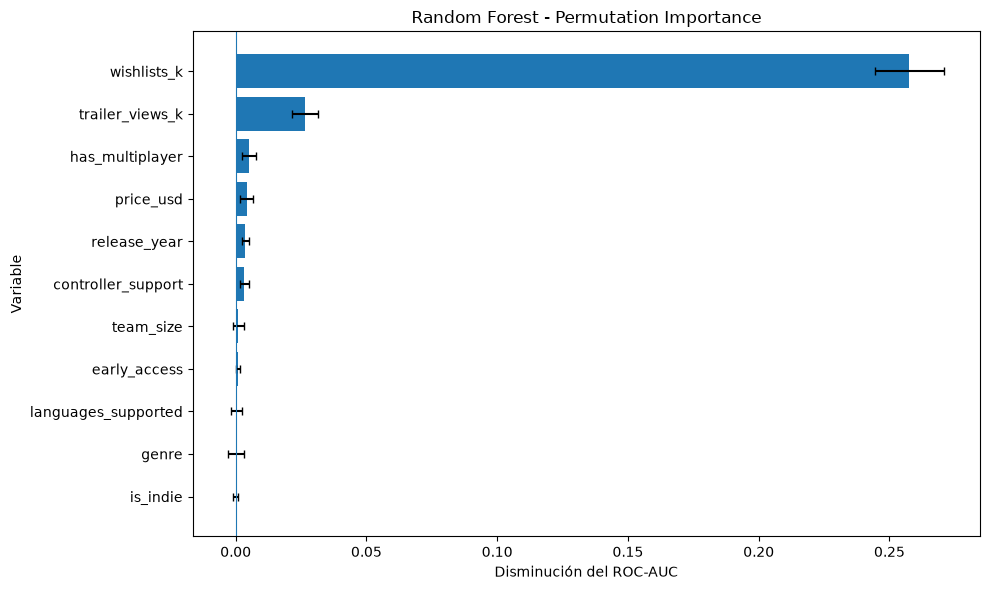

In [48]:

plt.figure(figsize=(10, 6))

plt.barh(
    permutation_df["Feature"],
    permutation_df["ROC-AUC Importance"],
    xerr=permutation_df["ROC-AUC Std"],
    capsize=3
)

plt.axvline(0, linewidth=0.8)
plt.xlabel("Disminución del ROC-AUC")
plt.ylabel("Variable")
plt.title("Random Forest - Permutation Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## feature ablation
entrenar nuevamente Random Forest quitando algunas variables y comparar si realmente perdemos rendimiento.

In [49]:

feature_sets = {
    "A - Original": feature_cols,

    "B - Sin genre": [
        col for col in feature_cols
        if col != "genre"
    ],

    "C - Reducido": [
        col for col in feature_cols
        if col not in [
            "genre",
            "languages_supported",
            "is_indie",
            "early_access"
        ]
    ],

    "D - Señales principales": [
        "wishlists_k",
        "trailer_views_k",
        "team_size",
        "price_usd",
        "release_year"
    ]
}

print("Experimentos preparados:\n")

for name, features in feature_sets.items():
    print(f"{name}: {len(features)} variables")
    print(features)
    print()


Experimentos preparados:

A - Original: 11 variables
['genre', 'release_year', 'is_indie', 'team_size', 'price_usd', 'has_multiplayer', 'early_access', 'controller_support', 'languages_supported', 'wishlists_k', 'trailer_views_k']

B - Sin genre: 10 variables
['release_year', 'is_indie', 'team_size', 'price_usd', 'has_multiplayer', 'early_access', 'controller_support', 'languages_supported', 'wishlists_k', 'trailer_views_k']

C - Reducido: 7 variables
['release_year', 'team_size', 'price_usd', 'has_multiplayer', 'controller_support', 'wishlists_k', 'trailer_views_k']

D - Señales principales: 5 variables
['wishlists_k', 'trailer_views_k', 'team_size', 'price_usd', 'release_year']



In [50]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

rf_experiment_models = {}
rf_experiment_results = []

for experiment_name, features in feature_sets.items():

    # Identificar las columnas presentes en este experimento
    numeric = [col for col in numeric_cols if col in features]
    binary = [col for col in binary_cols if col in features]
    categorical = ["genre"] if "genre" in features else []

    # Preprocesamiento
    experiment_preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", "passthrough", numeric),
            ("binary", "passthrough", binary),
            ("genre", OneHotEncoder(handle_unknown="ignore"), categorical)
        ],
        remainder="drop"
    )

    # Modelo
    model = Pipeline(steps=[
        ("preprocessor", experiment_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Entrenamiento
    model.fit(X_train[features], y_train)

    # Predicciones sobre validation
    probabilities = model.predict_proba(X_val[features])[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    # Métricas
    metrics = {
        "Experiment": experiment_name,
        "Features": len(features),
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Average Precision": average_precision_score(y_val, probabilities)
    }

    rf_experiment_models[experiment_name] = model
    rf_experiment_results.append(metrics)

# Tabla comparativa
rf_experiment_df = pd.DataFrame(rf_experiment_results)

display(
    rf_experiment_df
    .sort_values("ROC-AUC", ascending=False)
    .reset_index(drop=True)
    .round(4)
)


,Experiment,Features,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,C - Reducido,7,0.8650,0.7406,0.7191,0.5333,0.6124,0.8984,0.6887
1,A - Original,11,0.8583,0.7193,0.7134,0.4875,0.5792,0.8957,0.6970
2,B - Sin genre,10,0.8633,0.7349,0.7184,0.5208,0.6039,0.8957,0.6901
3,D - Señales principales,5,0.8650,0.7422,0.7167,0.5375,0.6143,0.8886,0.6796


In [51]:

from sklearn.metrics import precision_recall_curve

threshold_comparison = []

for experiment_name, model in rf_experiment_models.items():

    features = feature_sets[experiment_name]

    probabilities = model.predict_proba(X_val[features])[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val,
        probabilities
    )

    # El último elemento de precision y recall no tiene threshold.
    precision = precision[:-1]
    recall = recall[:-1]

    f1_values = (
        2 * precision * recall /
        (precision + recall + 1e-10)
    )

    # Mejor F1
    best_f1_idx = np.argmax(f1_values)

    # Mayor Recall manteniendo Precision >= 0.60
    valid_indices = np.where(precision >= 0.60)[0]

    if len(valid_indices) > 0:
        best_recall_idx = valid_indices[
            np.argmax(recall[valid_indices])
        ]

        threshold_comparison.append({
            "Experiment": experiment_name,
            "Strategy": "Maximum Recall (Precision >= 0.60)",
            "Threshold": thresholds[best_recall_idx],
            "Precision": precision[best_recall_idx],
            "Recall": recall[best_recall_idx],
            "F1": f1_values[best_recall_idx]
        })

    threshold_comparison.append({
        "Experiment": experiment_name,
        "Strategy": "Maximum F1",
        "Threshold": thresholds[best_f1_idx],
        "Precision": precision[best_f1_idx],
        "Recall": recall[best_f1_idx],
        "F1": f1_values[best_f1_idx]
    })

threshold_comparison_df = pd.DataFrame(threshold_comparison)

display(
    threshold_comparison_df
    .sort_values(["Strategy", "F1"], ascending=[True, False])
    .reset_index(drop=True)
    .round(4)
)


,Experiment,Strategy,Threshold,Precision,Recall,F1
0,A - Original,Maximum F1,0.3300,0.6263,0.7333,0.6756
1,D - Señales principales,Maximum F1,0.3667,0.6445,0.6875,0.6653
2,B - Sin genre,Maximum F1,0.3367,0.5925,0.7208,0.6504
3,C - Reducido,Maximum F1,0.2667,0.5455,0.8000,0.6486
4,A - Original,Maximum Recall (Precision >= 0.60),0.3033,0.6040,0.7625,0.6740
5,D - Señales principales,Maximum Recall (Precision >= 0.60),0.3333,0.6085,0.7125,0.6564
6,B - Sin genre,Maximum Recall (Precision >= 0.60),0.3467,0.6014,0.7042,0.6488
7,C - Reducido,Maximum Recall (Precision >= 0.60),0.3667,0.6000,0.6625,0.6297


In [52]:
rf_experiment_df.to_csv(
    "random_forest_feature_experiments.csv",
    index=False
)

threshold_comparison_df.to_csv(
    "random_forest_threshold_experiments.csv",
    index=False
)

In [55]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Separación de variables
numeric_cols = [
    "release_year",
    "team_size",
    "price_usd",
    "languages_supported",
    "wishlists_k",
    "trailer_views_k"
]

binary_cols = [
    "is_indie",
    "has_multiplayer",
    "early_access",
    "controller_support"
]

categorical_cols = ["genre"]

# Preprocesamiento específico para Random Forest
rf_tuned_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_cols),
        ("binary", "passthrough", binary_cols),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ],
    remainder="drop"
)

# Pipeline independiente
rf_tuning_pipeline = Pipeline([
    ("preprocessor", rf_tuned_preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Espacio de búsqueda
rf_param_distributions = {
    "classifier__n_estimators": [200, 300, 500, 700],
    "classifier__max_depth": [None, 10, 15, 20, 30],
    "classifier__min_samples_split": [2, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 4, 8],
    "classifier__max_features": ["sqrt", "log2", 0.7],
    "classifier__class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ],
    "classifier__max_samples": [None, 0.7, 0.85]
}

# Validación cruzada estratificada
rf_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Búsqueda aleatoria
rf_tuned_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=30,
    scoring="average_precision",
    cv=rf_cv,
    refit=True,
    random_state=42,
    n_jobs=1,  # CAMBIO: ejecución secuencial
    verbose=2,
    return_train_score=True
)

print("Pipeline y búsqueda preparados.")
print("Combinaciones:", 30)
print("Folds por combinación:", 3)
print("Total de ajustes:", 90)


Pipeline y búsqueda preparados.
Combinaciones: 30
Folds por combinación: 3
Total de ajustes: 90


In [56]:
rf_tuned_search.fit(X_train, y_train)

rf_tuned_model = rf_tuned_search.best_estimator_
rf_tuned_best_params = rf_tuned_search.best_params_

print("Mejor Average Precision promedio (CV):")
print(round(rf_tuned_search.best_score_, 4))

print("\nMejores hiperparámetros:")
for param, value in rf_tuned_best_params.items():
    print(f"{param}: {value}")


Fitting 3 folds for each of 30 candidates, totalling 90 fits
[CV] END classifier__class_weight=balanced_subsample, classifier__max_depth=15, classifier__max_features=log2, classifier__max_samples=0.85, classifier__min_samples_leaf=4, classifier__min_samples_split=5, classifier__n_estimators=500; total time=   1.9s
[CV] END classifier__class_weight=balanced_subsample, classifier__max_depth=15, classifier__max_features=log2, classifier__max_samples=0.85, classifier__min_samples_leaf=4, classifier__min_samples_split=5, classifier__n_estimators=500; total time=   1.9s
[CV] END classifier__class_weight=balanced_subsample, classifier__max_depth=15, classifier__max_features=log2, classifier__max_samples=0.85, classifier__min_samples_leaf=4, classifier__min_samples_split=5, classifier__n_estimators=500; total time=   1.8s
[CV] END classifier__class_weight=None, classifier__max_depth=10, classifier__max_features=log2, classifier__max_samples=0.7, classifier__min_samples_leaf=2, classifier__min_

In [57]:
rf_tuned_model = rf_tuned_search.best_estimator_

y_val_proba_rf_tuned = rf_tuned_model.predict_proba(X_val)[:, 1]
y_val_pred_rf_tuned = (y_val_proba_rf_tuned >= 0.5).astype(int)

print("Random Forest optimizado - Validation")
print(classification_report(y_val, y_val_pred_rf_tuned, digits=4))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_rf_tuned))
print("Average Precision:", average_precision_score(y_val, y_val_proba_rf_tuned))
print("Matriz de confusión:")
print(confusion_matrix(y_val, y_val_pred_rf_tuned))

Random Forest optimizado - Validation
              precision    recall  f1-score   support

           0     0.8774    0.9615    0.9175       960
           1     0.7500    0.4625    0.5722       240

    accuracy                         0.8617      1200
   macro avg     0.8137    0.7120    0.7448      1200
weighted avg     0.8519    0.8617    0.8484      1200

ROC-AUC: 0.8999262152777778
Average Precision: 0.7173337226017047
Matriz de confusión:
[[923  37]
 [129 111]]


In [58]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(
    y_val, y_val_proba_rf_tuned
)

# Excluir el último punto: no tiene un threshold asociado.
precision_t = precision[:-1]
recall_t = recall[:-1]

f1_scores = (
    2 * precision_t * recall_t /
    (precision_t + recall_t + 1e-12)
)

# Criterio 1: máximo Recall con Precision >= 0.60
valid = precision_t >= 0.60

if valid.any():
    valid_indices = np.where(valid)[0]
    best_recall_idx = valid_indices[np.argmax(recall_t[valid])]

    print("Máximo Recall con Precision >= 0.60")
    print(f"Threshold: {thresholds[best_recall_idx]:.4f}")
    print(f"Precision: {precision_t[best_recall_idx]:.4f}")
    print(f"Recall: {recall_t[best_recall_idx]:.4f}")
    print(f"F1: {f1_scores[best_recall_idx]:.4f}")

# Criterio 2: máximo F1
best_f1_idx = np.argmax(f1_scores)

print("\nMáximo F1")
print(f"Threshold: {thresholds[best_f1_idx]:.4f}")
print(f"Precision: {precision_t[best_f1_idx]:.4f}")
print(f"Recall: {recall_t[best_f1_idx]:.4f}")
print(f"F1: {f1_scores[best_f1_idx]:.4f}")

Máximo Recall con Precision >= 0.60
Threshold: 0.2906
Precision: 0.6006
Recall: 0.7708
F1: 0.6752

Máximo F1
Threshold: 0.2922
Precision: 0.6086
Recall: 0.7708
F1: 0.6801


In [59]:
selected_threshold_rf_tuned = 0.2906

y_val_pred_rf_tuned_selected = (
    y_val_proba_rf_tuned >= selected_threshold_rf_tuned
).astype(int)

print("Random Forest optimizado - Threshold 0.2906")
print("Matriz de confusión:")
print(confusion_matrix(y_val, y_val_pred_rf_tuned_selected))

print("\nReporte:")
print(classification_report(
    y_val,
    y_val_pred_rf_tuned_selected,
    digits=4
))

Random Forest optimizado - Threshold 0.2906
Matriz de confusión:
[[838 122]
 [ 55 185]]

Reporte:
              precision    recall  f1-score   support

           0     0.9384    0.8729    0.9045       960
           1     0.6026    0.7708    0.6764       240

    accuracy                         0.8525      1200
   macro avg     0.7705    0.8219    0.7904      1200
weighted avg     0.8712    0.8525    0.8589      1200



In [60]:
print("Threshold principal exacto:",
      repr(float(thresholds[best_recall_idx])))

print("Threshold de máximo F1 exacto:",
      repr(float(thresholds[best_f1_idx])))

Threshold principal exacto: 0.29059821131498603
Threshold de máximo F1 exacto: 0.2921768217278801


In [61]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Umbral seleccionado previamente en validation
final_rf_threshold = 0.29059821131498603

# Predicciones sobre test
y_test_proba_rf_tuned = rf_tuned_model.predict_proba(X_test)[:, 1]

y_test_pred_rf_tuned = (
    y_test_proba_rf_tuned >= final_rf_threshold
).astype(int)

# Métricas
print("RANDOM FOREST OPTIMIZADO - TEST")
print(f"Threshold: {final_rf_threshold:.16f}")
print(f"Accuracy:          {accuracy_score(y_test, y_test_pred_rf_tuned):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_test_pred_rf_tuned):.4f}")
print(f"Precision:         {precision_score(y_test, y_test_pred_rf_tuned):.4f}")
print(f"Recall:            {recall_score(y_test, y_test_pred_rf_tuned):.4f}")
print(f"F1:                {f1_score(y_test, y_test_pred_rf_tuned):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, y_test_proba_rf_tuned):.4f}")
print(f"Average Precision: {average_precision_score(y_test, y_test_proba_rf_tuned):.4f}")

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_test_pred_rf_tuned))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_test_pred_rf_tuned, digits=4))

RANDOM FOREST OPTIMIZADO - TEST
Threshold: 0.2905982113149860
Accuracy:          0.8358
Balanced Accuracy: 0.7943
Precision:         0.5705
Recall:            0.7250
F1:                0.6385
ROC-AUC:           0.8875
Average Precision: 0.7069

Matriz de confusión:
[[829 131]
 [ 66 174]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0     0.9263    0.8635    0.8938       960
           1     0.5705    0.7250    0.6385       240

    accuracy                         0.8358      1200
   macro avg     0.7484    0.7943    0.7662      1200
weighted avg     0.8551    0.8358    0.8427      1200



In [68]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mlp_test_model = GameSuccessMLP(
    num_numeric_features=len(numeric_cols) + len(binary_cols),
    num_genres=len(genre_to_idx),
    embedding_dim=6
).to(device)

mlp_test_model.load_state_dict(best_model_state)
mlp_test_model.eval()

print("MLP reconstruido correctamente.")
print(f"Variables numéricas + binarias: {len(numeric_cols) + len(binary_cols)}")
print(f"Dimensión del embedding: 6")
print(f"Entrada total: {len(numeric_cols) + len(binary_cols) + 6}")
print(f"Dispositivo: {device}")

MLP reconstruido correctamente.
Variables numéricas + binarias: 10
Dimensión del embedding: 6
Entrada total: 16
Dispositivo: cuda


In [69]:
print("Variables relacionadas con el preprocesamiento del MLP:\n")

for name, obj in globals().copy().items():
    name_lower = name.lower()

    if any(term in name_lower for term in [
        "scaler", "genre", "numeric", "binary",
        "mlp", "tensor", "encoded", "transform"
    ]):
        if name in ["GameSuccessMLP", "mlp_test_model"]:
            continue

        shape = getattr(obj, "shape", None)
        print(f"{name}: {type(obj).__name__}" +
              (f" | shape={shape}" if shape is not None else ""))

Variables relacionadas con el preprocesamiento del MLP:

numeric_cols: list
ColumnTransformer: ABCMeta
StandardScaler: type
binary_cols: list
genres: list
genre_to_idx: dict
encode_genre: function
genre_train: ndarray | shape=(5600,)
genre_val: ndarray | shape=(1200,)
genre_test: ndarray | shape=(1200,)
TensorDataset: type
X_train_tensor: Tensor | shape=torch.Size([5600, 10])
X_val_tensor: Tensor | shape=torch.Size([1200, 10])
X_test_tensor: Tensor | shape=torch.Size([1200, 10])
genre_train_tensor: Tensor | shape=torch.Size([5600])
genre_val_tensor: Tensor | shape=torch.Size([1200])
genre_test_tensor: Tensor | shape=torch.Size([1200])
y_train_tensor: Tensor | shape=torch.Size([5600])
y_val_tensor: Tensor | shape=torch.Size([1200])
y_test_tensor: Tensor | shape=torch.Size([1200])
x_genre: Tensor | shape=torch.Size([48])
mlp_val_probs: ndarray | shape=(1200,)
numeric: list
binary: list


In [70]:
# Verificar que el MLP reconstruido reproduce las probabilidades originales

with torch.no_grad():
    val_logits = mlp_test_model(
        X_val_tensor.to(device),
        genre_val_tensor.to(device)
    )

    mlp_val_probs_check = torch.sigmoid(val_logits).cpu().numpy().ravel()

print(f"Probabilidades originales: {mlp_val_probs.shape}")
print(f"Probabilidades reconstruidas: {mlp_val_probs_check.shape}")
print(f"Diferencia absoluta máxima: {np.max(np.abs(mlp_val_probs - mlp_val_probs_check)):.12f}")
print(f"Correlación: {np.corrcoef(mlp_val_probs, mlp_val_probs_check)[0, 1]:.12f}")

Probabilidades originales: (1200,)
Probabilidades reconstruidas: (1200,)
Diferencia absoluta máxima: 0.000000000000
Correlación: 1.000000000000


In [71]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Umbrales definidos exclusivamente con validation
thresholds = {
    "Logistic Regression": 0.2316,
    "Random Forest baseline": 0.3033,
    "Random Forest optimizado": 0.29059821131498603,
    "MLP + Entity Embedding": 0.3495
}

# Obtener probabilidades sobre test
with torch.no_grad():
    mlp_test_logits = mlp_test_model(
        X_test_tensor.to(device),
        genre_test_tensor.to(device)
    )
    mlp_test_probs = torch.sigmoid(mlp_test_logits).cpu().numpy().ravel()

models_probs_test = {
    "Logistic Regression": logistic_model.predict_proba(X_test)[:, 1],
    "Random Forest baseline": rf_model.predict_proba(X_test)[:, 1],
    "Random Forest optimizado": rf_tuned_model.predict_proba(X_test)[:, 1],
    "MLP + Entity Embedding": mlp_test_probs
}

y_true = y_test.to_numpy()

# Evaluación con umbrales fijos
test_results = []

for name, probs in models_probs_test.items():
    threshold = thresholds[name]
    predictions = (probs >= threshold).astype(int)

    test_results.append({
        "Modelo": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probs),
        "Average Precision": average_precision_score(y_true, probs),
        "Confusion Matrix": confusion_matrix(y_true, predictions)
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.drop(columns=["Confusion Matrix"])
    .round(4)
    .set_index("Modelo")
)

print("\nMATRICES DE CONFUSIÓN")
for result in test_results:
    print(f"\n{result['Modelo']} (threshold={result['Threshold']:.6f})")
    print(result["Confusion Matrix"])

,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Modelo,,,,,,,,
Logistic Regression,0.2316,0.8417,0.7870,0.5880,0.6958,0.6374,0.8676,0.6840
Random Forest baseline,0.3033,0.8358,0.7865,0.5729,0.7042,0.6318,0.8825,0.6831
Random Forest optimizado,0.2906,0.8358,0.7943,0.5705,0.7250,0.6385,0.8875,0.7069
MLP + Entity Embedding,0.3495,0.8350,0.7844,0.5714,0.7000,0.6292,0.8812,0.6875



MATRICES DE CONFUSIÓN

Logistic Regression (threshold=0.231600)
[[843 117]
 [ 73 167]]

Random Forest baseline (threshold=0.303300)
[[834 126]
 [ 71 169]]

Random Forest optimizado (threshold=0.290598)
[[829 131]
 [ 66 174]]

MLP + Entity Embedding (threshold=0.349500)
[[834 126]
 [ 72 168]]
